# 01 — Data preprocessing and exploration

This notebook demonstrates practical cleaning choices on the real BTS 2025–2026 extracts. We keep passenger zeros because they can represent valid reported records; we reject missing identifiers, impossible dates, and negative counts. We aggregate repeated rows at carrier–route–month level and inspect outliers instead of automatically deleting busy travel periods.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="crest")
ROOT = Path.cwd()
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

def read_archive(path):
    with ZipFile(path) as z:
        name = next(n for n in z.namelist() if n.lower().endswith(".csv"))
        with z.open(name) as f:
            return pd.read_csv(f, low_memory=False)

raw = pd.concat([
    read_archive(RAW / "bts_t100_market_2025.zip"),
    read_archive(RAW / "bts_t100_market_2026.zip")
], ignore_index=True)
raw.columns = raw.columns.str.strip().str.upper()
raw.shape, raw.head()

((519402, 10),    PASSENGERS  DISTANCE UNIQUE_CARRIER  ... DEST  YEAR MONTH
0         0.0       0.0            1BQ  ...  GPT  2025     2
1         0.0       0.0            27Q  ...  OPF  2025    12
2         0.0       0.0            27Q  ...  TEB  2025    11
3         0.0       0.0            3AQ  ...  CKU  2025     8
4         0.0       0.0            3AQ  ...  HOM  2025    12

[5 rows x 10 columns])


## 1. Inspect quality before changing anything
Check missing values, duplicate keys, data types, date range, and passenger values. The same route/carrier/month may occur more than once in the original extract, so the final key will be created by aggregation rather than silently dropping records.

In [2]:
required = ["PASSENGERS", "DISTANCE", "UNIQUE_CARRIER", "ORIGIN", "DEST", "YEAR", "MONTH"]
missing_fields = sorted(set(required) - set(raw.columns))
if missing_fields:
    raise ValueError(f"Missing expected BTS fields: {missing_fields}")

quality = pd.DataFrame({
    "missing_count": raw[required].isna().sum(),
    "missing_percent": (raw[required].isna().mean() * 100).round(3),
    "dtype": raw[required].dtypes.astype(str)
})
display(quality)
print("Raw rows:", f"{len(raw):,}")
print("Raw exact duplicate rows:", f'{raw.duplicated().sum():,}')
print("Month coverage:", sorted(zip(raw.YEAR.unique(), raw.MONTH.unique()))[:5], "…")
print("Passenger minimum/maximum:", raw.PASSENGERS.min(), raw.PASSENGERS.max())

                missing_count  missing_percent    dtype
PASSENGERS                  0              0.0  float64
DISTANCE                    0              0.0  float64
UNIQUE_CARRIER              0              0.0   object
ORIGIN                      0              0.0   object
DEST                        0              0.0   object
YEAR                        0              0.0    int64
MONTH                       0              0.0    int64
Raw rows: 519,402
Raw exact duplicate rows: 2,256
Month coverage: [(np.int64(2025), np.int64(2)), (np.int64(2026), np.int64(12))] …
Passenger minimum/maximum: 0.0 89829.0


## 2. Clean, validate, and aggregate
We normalize text categories, coerce numeric values, remove unusable rows, and create a proper first-of-month date. If the source has repeated records for a carrier-route-month, passenger counts and distance are combined using sum and mean respectively. The final CSV is reproducible from the raw archives.

In [3]:
df = raw.copy()
raw_row_count = len(df)
for col in ["UNIQUE_CARRIER", "UNIQUE_CARRIER_NAME", "ORIGIN", "DEST"]:
    if col in df:
        df[col] = df[col].astype("string").str.strip().str.upper()

for col in ["PASSENGERS", "DISTANCE", "YEAR", "MONTH", "ORIGIN_AIRPORT_ID", "DEST_AIRPORT_ID"]:
    if col in df:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Conditional imputations: apply only when values are actually missing. Never invent missing target or route identity.
missing_before = df.isna().sum()
if "DISTANCE" in df:
    df["DISTANCE"] = df.groupby(["UNIQUE_CARRIER", "ORIGIN", "DEST"], dropna=False)["DISTANCE"].transform(lambda s: s.fillna(s.median()))
    df["DISTANCE"] = df["DISTANCE"].fillna(df["DISTANCE"].median())
if "UNIQUE_CARRIER_NAME" in df and "UNIQUE_CARRIER" in df:
    df["UNIQUE_CARRIER_NAME"] = df["UNIQUE_CARRIER_NAME"].fillna(df.groupby("UNIQUE_CARRIER")["UNIQUE_CARRIER_NAME"].transform(lambda s: s.mode().iloc[0] if not s.mode().empty else pd.NA))
    df["UNIQUE_CARRIER_NAME"] = df["UNIQUE_CARRIER_NAME"].fillna("UNKNOWN")
print("Conditional imputation counts:")
display(pd.DataFrame({"missing_before":missing_before, "missing_after":df.isna().sum()}).fillna(0).astype(int))

df = df.dropna(subset=["PASSENGERS", "YEAR", "MONTH", "UNIQUE_CARRIER", "ORIGIN", "DEST"] + (["DISTANCE"] if "DISTANCE" in df else []))
df = df[(df["PASSENGERS"] >= 0) & df["MONTH"].between(1, 12)]
df = df[df["ORIGIN"].ne("") & df["DEST"].ne("") & df["ORIGIN"].ne("<NA>") & df["DEST"].ne("<NA>")]
df["YEAR"] = df["YEAR"].astype(int)
df["MONTH"] = df["MONTH"].astype(int)
df["DATE"] = pd.to_datetime(dict(year=df.YEAR, month=df.MONTH, day=1))
print(f"Removed {raw_row_count-len(df):,} incomplete/invalid rows; retained {len(df):,}.")

keys = ["DATE", "YEAR", "MONTH", "UNIQUE_CARRIER", "UNIQUE_CARRIER_NAME",
        "ORIGIN", "DEST", "ORIGIN_AIRPORT_ID", "DEST_AIRPORT_ID"]
monthly = (df.groupby(keys, dropna=False, as_index=False)
             .agg(PASSENGERS=("PASSENGERS", "sum"),
                  DISTANCE=("DISTANCE", "mean")))
monthly = monthly.sort_values(["DATE", "ORIGIN", "DEST", "UNIQUE_CARRIER"]).reset_index(drop=True)
monthly.to_csv(OUT / "air_passenger_monthly.csv", index=False)
print("Clean monthly rows:", f"{len(monthly):,}")
print("Saved:", OUT / "air_passenger_monthly.csv")
display(monthly.head())


Conditional imputation counts:
                     missing_before  missing_after
PASSENGERS                        0              0
DISTANCE                          0              0
UNIQUE_CARRIER                    0              0
UNIQUE_CARRIER_NAME               0              0
ORIGIN_AIRPORT_ID                 0              0
ORIGIN                            0              0
DEST_AIRPORT_ID                   0              0
DEST                              0              0
YEAR                              0              0
MONTH                             0              0
Removed 0 incomplete/invalid rows; retained 519,402.
Clean monthly rows: 503,224
Saved: C:\Users\MY PC\OneDrive - The Northcap university\Documents\ChatGPT\ai passenger tracker\data\processed\air_passenger_monthly.csv
        DATE  YEAR  MONTH  ... DEST_AIRPORT_ID PASSENGERS DISTANCE
0 2025-01-01  2025      1  ...           10056        3.0     18.0
1 2025-01-01  2025      1  ...           15256        0.

## 3. Look at unusual passenger counts
Large counts are not automatically errors: the busiest routes should naturally stand out. We use the IQR rule to *flag* possible outliers, then preserve them unless the source record is invalid. This is more appropriate than deleting real peaks from an airline-demand dataset.

IQR upper flag: 10,708 passengers per carrier-route-month
Rows above flag: 41,921
Rows with zero passengers: 82,515


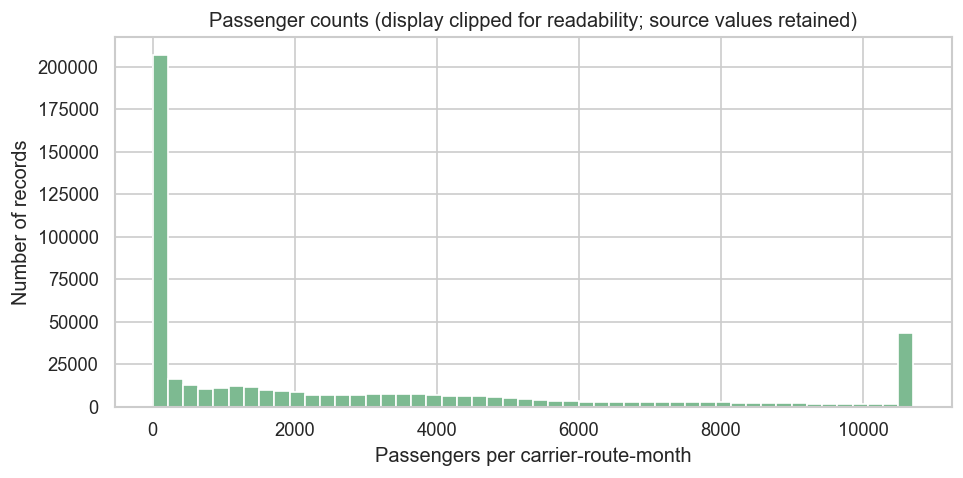

In [4]:
q1, q3 = monthly.PASSENGERS.quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print("IQR upper flag:", f"{upper:,.0f}", "passengers per carrier-route-month")
print("Rows above flag:", f"{(monthly.PASSENGERS > upper).sum():,}")
print("Rows with zero passengers:", f"{(monthly.PASSENGERS == 0).sum():,}")
monthly.PASSENGERS.clip(upper=upper).hist(bins=50, figsize=(9, 4))
plt.title("Passenger counts (display clipped for readability; source values retained)")
plt.xlabel("Passengers per carrier-route-month")
plt.ylabel("Number of records")
plt.show()

## 4. Explore recent traffic
We compare reported passenger totals by month and display the busiest airport pairs. The 2026 line is year-to-date and must not be read as a complete-year total.

         DATE   PASSENGERS
11 2025-12-01   92146961.0
12 2026-01-01   79645464.0
13 2026-02-01   76884283.0
14 2026-03-01   93999761.0
15 2026-04-01   90450847.0
16 2026-05-01   95323217.0
17 2026-06-01   97745648.0
18 2026-07-01  101606380.0


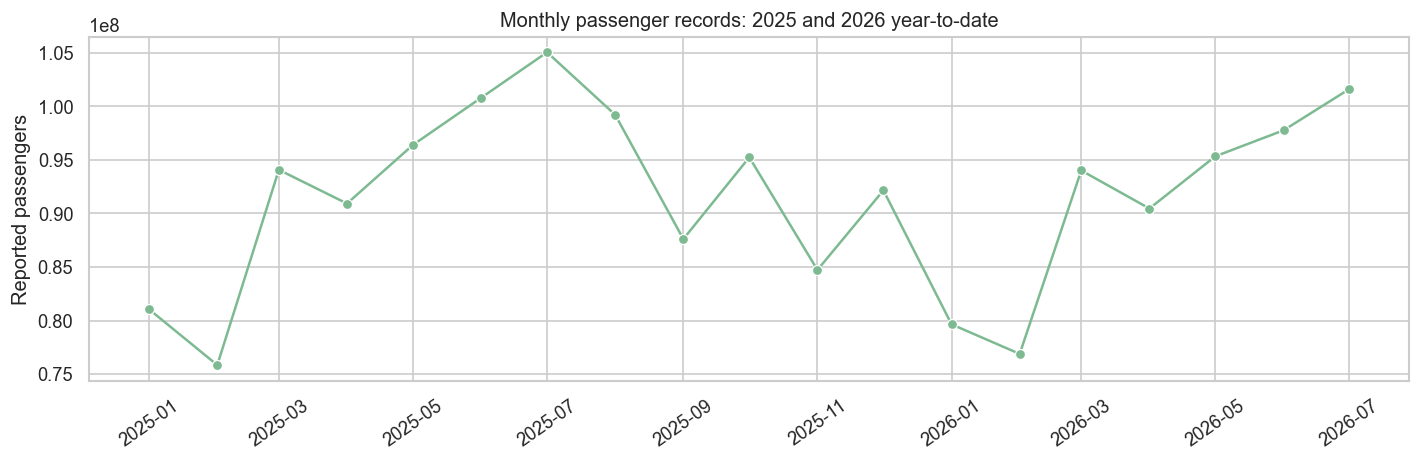

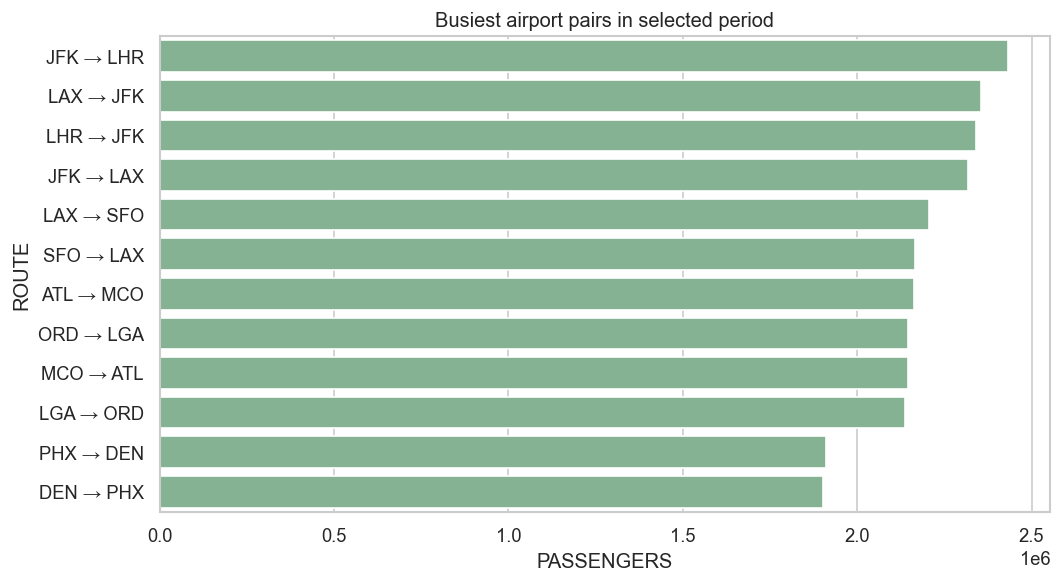

In [5]:
monthly_totals = monthly.groupby("DATE", as_index=False).PASSENGERS.sum()
plt.figure(figsize=(12, 4))
sns.lineplot(data=monthly_totals, x="DATE", y="PASSENGERS", marker="o")
plt.title("Monthly passenger records: 2025 and 2026 year-to-date")
plt.ylabel("Reported passengers")
plt.xlabel("")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

route_totals = (monthly.assign(ROUTE=monthly.ORIGIN + " → " + monthly.DEST)
                .groupby("ROUTE", as_index=False).PASSENGERS.sum()
                .nlargest(12, "PASSENGERS"))
plt.figure(figsize=(9, 5))
sns.barplot(data=route_totals, x="PASSENGERS", y="ROUTE")
plt.title("Busiest airport pairs in selected period")
plt.tight_layout()
plt.show()
display(monthly_totals.tail(8))

### Preprocessing decisions to report
- Missing target or route identity: removed and counted.
- Month outside 1–12 / negative passengers: treated as invalid.
- Zero passengers: retained.
- Repeated carrier-route-month rows: aggregated.
- Outlier passenger counts: flagged and visualized, not deleted.
- Model validation: time-based split (train on 2025, evaluate on 2026).


## Workbook audit: profile every source column

This section reports the shape, dtype, descriptive statistics, missing count and missing percentage for **every column in the combined raw BTS extract**. It also lists numerical and categorical columns separately. The report is generated from the loaded file, so it stays correct if the supplied extract changes.


In [6]:
# Full-column data understanding, before cleaning or aggregation.
print(f"Raw shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
column_audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing_count": raw.isna().sum(),
    "missing_percent": (raw.isna().mean() * 100).round(3),
    "unique_values": raw.nunique(dropna=True),
})
column_audit["example_values"] = [raw[c].dropna().astype(str).head(3).tolist() for c in raw.columns]
display(column_audit)
numerical_columns = raw.select_dtypes(include=np.number).columns.tolist()
categorical_columns = raw.select_dtypes(include=["object", "string", "category", "bool"]).columns.tolist()
print("Numerical columns:", numerical_columns)
print("Categorical/text columns:", categorical_columns)
display(raw.describe(include="all").T)


Raw shape: 519,402 rows × 10 columns
                       dtype  ...                                     example_values
PASSENGERS           float64  ...                                    [0.0, 0.0, 0.0]
DISTANCE             float64  ...                                    [0.0, 0.0, 0.0]
UNIQUE_CARRIER        object  ...                                    [1BQ, 27Q, 27Q]
UNIQUE_CARRIER_NAME   object  ...  [Eastern Airlines f/k/a Dynamic Airways, LLC, ...
ORIGIN_AIRPORT_ID      int64  ...                              [11973, 13898, 15167]
ORIGIN                object  ...                                    [GPT, OPF, TEB]
DEST_AIRPORT_ID        int64  ...                              [11973, 13898, 15167]
DEST                  object  ...                                    [GPT, OPF, TEB]
YEAR                   int64  ...                                 [2025, 2025, 2025]
MONTH                  int64  ...                                        [2, 12, 11]

[10 rows x 6 columns]
Numer

## Missing-value decisions, encoding types, bins, scaling, and outliers

The BTS extract is expected to be substantially complete. We do not claim that an imputer ran when there are no missing values. The table below states the reproducible policy for each source field: remove rows only when target/route/time identity cannot be recovered; use a group median for a missing distance if one occurs; use a mode or explicit `UNKNOWN` for descriptive labels. Numeric BTS IDs are identifiers, not quantities, so they are excluded from model inputs. Airline and airport codes are **nominal** (no order); the derived high-demand target is **binary**; this dataset has no genuine ordinal input category, so we do not invent an order.


In [7]:
# Per-column action table. Values actually imputed/dropped are also reported.
missing_decisions = []
for col in raw.columns:
    count = int(raw[col].isna().sum())
    if col in {"PASSENGERS", "YEAR", "MONTH", "UNIQUE_CARRIER", "ORIGIN", "DEST"}:
        action, reason = "Drop row if missing", "Target or route/time identity is essential; it cannot be safely inferred."
    elif col == "DISTANCE":
        action, reason = "Group median (carrier + route); drop if still missing", "Distance is numeric and route-specific; a group median preserves route context."
    elif col in {"UNIQUE_CARRIER_NAME"}:
        action, reason = "Mode within carrier code; otherwise UNKNOWN", "The code identifies the carrier; the label is descriptive metadata."
    elif "ID" in col.upper():
        action, reason = "Keep missing as missing; exclude from model", "Administrative identifiers are not analytical measurements."
    else:
        action, reason = "UNKNOWN constant for categorical / median for numeric", "Safe fallback depends on the observed data type; inspect before modeling."
    missing_decisions.append({"column":col,"missing_count":count,"missing_percent":round(100*count/len(raw),3),"policy":action,"reason":reason})
missing_decision_table = pd.DataFrame(missing_decisions)
display(missing_decision_table)
print("Observed missing cells:", int(raw.isna().sum().sum()))

# Explicit category types and project encodings.
encoding_plan = pd.DataFrame([
 {"field":"UNIQUE_CARRIER, UNIQUE_CARRIER_NAME, ORIGIN, DEST","kind":"Nominal","encoding":"OneHotEncoder(handle_unknown='ignore')","why":"Codes label groups; alphabetical/code order has no numeric meaning."},
 {"field":"HIGH_DEMAND (derived target)","kind":"Binary","encoding":"LabelEncoder demo: High=0, Normal=1; classifier target: Normal=0, High=1","why":"The encoder sorts labels alphabetically; the classifier explicitly sets High=1 as the positive class. Threshold comes from training data only."},
 {"field":"MONTH","kind":"Cyclical numeric","encoding":"sin/cos of month","why":"December and January are adjacent seasons; raw month numbers imply a false gap."},
 {"field":"Ordinal input","kind":"None in BTS fields used","encoding":"Not applicable","why":"No source field has a defensible ordered category. Do not fabricate one."},
])
display(encoding_plan)

# Equal-frequency bins are useful for communicating demand tiers. Ties (especially zero counts) can
# reduce the actual number of bins; duplicates='drop' handles that honestly. Binned target is descriptive only.
source_for_bins = monthly["PASSENGERS"].astype(float)
monthly["DEMAND_TIER"] = pd.qcut(source_for_bins.rank(method="first"), q=4, labels=["Low","Mid-low","Mid-high","High"])
print("Equal-frequency demand tiers; rank breaks ties reproducibly. Boundaries:")
display(pd.DataFrame({"tier":monthly.groupby("DEMAND_TIER",observed=False).PASSENGERS.agg(["min","max","count"]).index,
                      "min_passengers":monthly.groupby("DEMAND_TIER",observed=False).PASSENGERS.min().values,
                      "max_passengers":monthly.groupby("DEMAND_TIER",observed=False).PASSENGERS.max().values,
                      "rows":monthly.groupby("DEMAND_TIER",observed=False).PASSENGERS.size().values}))
print("Use: descriptive charts/communication. Do not feed this target-derived tier into a model predicting PASSENGERS (target leakage).")

# IQR review by numeric variable. Flagging is not automatic deletion: passenger peaks are plausible market demand.
for col in ["PASSENGERS", "DISTANCE"]:
    if col in monthly:
        vals = monthly[col].dropna()
        q1v, q3v = vals.quantile([.25,.75]); spread=q3v-q1v
        lo, hi=q1v-1.5*spread, q3v+1.5*spread
        nlow, nhigh=int((vals<lo).sum()),int((vals>hi).sum())
        print(f"{col}: IQR [{lo:,.2f}, {hi:,.2f}], lower flags={nlow:,}, upper flags={nhigh:,}.")
        if col == "PASSENGERS": print("Treatment: retain plausible high values and valid zeros; remove only impossible negative counts during validation.")
        else: print("Treatment: inspect route-distance flags; retain plausible long-haul values, reject only invalid negative distance; do not cap real routes.")

# Demonstrate transformations on training features only; log1p handles zero and right skew.
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
scale_demo = monthly[["DISTANCE"]].copy().replace([np.inf,-np.inf],np.nan)
scale_demo["DISTANCE_LOG1P"] = np.log1p(scale_demo["DISTANCE"].clip(lower=0))
scale_demo["DISTANCE_ZSCORE"] = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(scale_demo[["DISTANCE_LOG1P"]]))
print("Distance skew before/after log1p:", round(float(scale_demo.DISTANCE.skew()),3), round(float(scale_demo.DISTANCE_LOG1P.skew()),3))
display(scale_demo.describe().T)


                column  ...                                             reason
0           PASSENGERS  ...  Target or route/time identity is essential; it...
1             DISTANCE  ...  Distance is numeric and route-specific; a grou...
2       UNIQUE_CARRIER  ...  Target or route/time identity is essential; it...
3  UNIQUE_CARRIER_NAME  ...  The code identifies the carrier; the label is ...
4    ORIGIN_AIRPORT_ID  ...  Administrative identifiers are not analytical ...
5               ORIGIN  ...  Target or route/time identity is essential; it...
6      DEST_AIRPORT_ID  ...  Administrative identifiers are not analytical ...
7                 DEST  ...  Target or route/time identity is essential; it...
8                 YEAR  ...  Target or route/time identity is essential; it...
9                MONTH  ...  Target or route/time identity is essential; it...

[10 rows x 5 columns]
Observed missing cells: 0
                                               field  ...                         